<a href="https://colab.research.google.com/github/HashimK1411/MSc_Project/blob/main/02_RF_H1_CICIDS2017.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import sys
import tensorflow as tf

print("Python version:", sys.version)
print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

!nvidia-smi

Python version: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
TensorFlow version: 2.19.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Thu Sep 24 18:10:55 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P8             12W /   70W |       3MiB /  

In [ ]:
!pip install -q tensorflow_decision_forests==1.12.0 pyarrow

import os
import time
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
import tensorflow_decision_forests as tfdf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    classification_report,
    ConfusionMatrixDisplay
)

print("TensorFlow:", tf.__version__)
print("TF-DF:", tfdf.__version__)

TensorFlow: 2.19.0
TF-DF: 1.12.0


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/MSc_Project"

PROCESSED_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "CICIDS2017",
    "processed"
)

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "RF_H1_CIC"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models",
    "RF_H1_CIC"
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

TRAIN_PATH = os.path.join(
    PROCESSED_DIR,
    "cicids2017_train.parquet"
)

VAL_PATH = os.path.join(
    PROCESSED_DIR,
    "cicids2017_validation.parquet"
)

TEST_PATH = os.path.join(
    PROCESSED_DIR,
    "cicids2017_test.parquet"
)

LABEL_COL = "Label"

print("Training:", TRAIN_PATH)
print("Validation:", VAL_PATH)
print("Testing:", TEST_PATH)
print("Results:", RESULTS_DIR)
print("Models:", MODEL_DIR)

Training: /content/drive/MyDrive/MSc_Project/data/CICIDS2017/processed/cicids2017_train.parquet
Validation: /content/drive/MyDrive/MSc_Project/data/CICIDS2017/processed/cicids2017_validation.parquet
Testing: /content/drive/MyDrive/MSc_Project/data/CICIDS2017/processed/cicids2017_test.parquet
Results: /content/drive/MyDrive/MSc_Project/results/RF_H1_CIC
Models: /content/drive/MyDrive/MSc_Project/models/RF_H1_CIC


In [ ]:
print(
    "Train exists:",
    os.path.exists(TRAIN_PATH)
)

print(
    "Validation exists:",
    os.path.exists(VAL_PATH)
)

print(
    "Test exists:",
    os.path.exists(TEST_PATH)
)

Train exists: True
Validation exists: True
Test exists: True


In [ ]:
print("Loading training data...")
train_df = pd.read_parquet(
    TRAIN_PATH
)

print("Loading validation data...")
val_df = pd.read_parquet(
    VAL_PATH
)

print("Loading test data...")
test_df = pd.read_parquet(
    TEST_PATH
)

print("\nTraining:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

print(
    "\nNumber of classes:",
    train_df[LABEL_COL].nunique()
)

Loading training data...
Loading validation data...
Loading test data...

Training: (1764554, 79)
Validation: (378119, 79)
Testing: (378119, 79)

Number of classes: 15


In [ ]:
class_names = sorted(
    train_df[LABEL_COL]
    .astype(str)
    .unique()
    .tolist()
)

print("Class order:")

for idx, label in enumerate(class_names):
    print(idx, "->", label)

print(
    "\nNumber of classes:",
    len(class_names)
)

Class order:
0 -> BENIGN
1 -> Bot
2 -> DDoS
3 -> DoS GoldenEye
4 -> DoS Hulk
5 -> DoS Slowhttptest
6 -> DoS slowloris
7 -> FTP-Patator
8 -> Heartbleed
9 -> Infiltration
10 -> PortScan
11 -> SSH-Patator
12 -> Web Attack - Brute Force
13 -> Web Attack - SQL Injection
14 -> Web Attack - XSS

Number of classes: 15


In [ ]:
train_ds = tfdf.keras.pd_dataframe_to_tf_dataset(
    train_df,
    label=LABEL_COL,
    task=tfdf.keras.Task.CLASSIFICATION
)

val_ds = tfdf.keras.pd_dataframe_to_tf_dataset(
    val_df,
    label=LABEL_COL,
    task=tfdf.keras.Task.CLASSIFICATION
)

test_ds = tfdf.keras.pd_dataframe_to_tf_dataset(
    test_df,
    label=LABEL_COL,
    task=tfdf.keras.Task.CLASSIFICATION
)

print(
    "TF-DF datasets created successfully."
)

TF-DF datasets created successfully.


In [ ]:
TREE_CANDIDATES = [
    100,
    200,
    300
]

print(
    "RF-H1 tree candidates:",
    TREE_CANDIDATES
)

print("\nFixed parameters:")
print("max_depth = -1")
print("min_examples = 1")
print("num_candidate_attributes = 0")
print("bootstrap = True")
print("random_seed = 42")

RF-H1 tree candidates: [100, 200, 300]

Fixed parameters:
max_depth = -1
min_examples = 1
num_candidate_attributes = 0
bootstrap = True
random_seed = 42


In [ ]:
def evaluate_candidate(
    model,
    dataset,
    dataframe,
    class_names
):

    pred_probabilities = model.predict(
        dataset,
        verbose=0
    )

    pred_ids = np.argmax(
        pred_probabilities,
        axis=1
    )

    y_pred = np.array(
        class_names
    )[pred_ids]

    y_true = (
        dataframe[LABEL_COL]
        .astype(str)
        .to_numpy()
    )

    return {
        "Accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "Macro Precision": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Macro Recall": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Macro F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Weighted F1": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ),

        "Balanced Accuracy":
            balanced_accuracy_score(
                y_true,
                y_pred
            ),

        "MCC": matthews_corrcoef(
            y_true,
            y_pred
        )
    }

In [ ]:
rf_h1_100 = tfdf.keras.RandomForestModel(
    num_trees=100,
    max_depth=-1,
    min_examples=1,
    num_candidate_attributes=0,
    bootstrap_training_dataset=True,
    bootstrap_size_ratio=1.0,
    sampling_with_replacement=True,
    random_seed=42,
    compute_oob_performances=True,
    verbose=2
)

rf_h1_100.compile(
    metrics=["accuracy"]
)

start_time = time.time()

rf_h1_100.fit(
    train_ds
)

time_100 = (
    time.time() - start_time
)

print(
    f"\nRF-H1-100 training time: "
    f"{time_100:.2f} seconds"
)

Use 8 thread(s) for training
Use /tmp/tmplm113ef3 as temporary training directory
Reading training dataset...
Training tensor examples:
Features: {'Destination_Port': <tf.Tensor 'data:0' shape=(None,) dtype=float32>, 'Flow_Duration': <tf.Tensor 'data_1:0' shape=(None,) dtype=float64>, 'Total_Fwd_Packets': <tf.Tensor 'data_2:0' shape=(None,) dtype=float32>, 'Total_Backward_Packets': <tf.Tensor 'data_3:0' shape=(None,) dtype=float32>, 'Total_Length_of_Fwd_Packets': <tf.Tensor 'data_4:0' shape=(None,) dtype=float32>, 'Total_Length_of_Bwd_Packets': <tf.Tensor 'data_5:0' shape=(None,) dtype=float64>, 'Fwd_Packet_Length_Max': <tf.Tensor 'data_6:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Min': <tf.Tensor 'data_7:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Mean': <tf.Tensor 'data_8:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Std': <tf.Tensor 'data_9:0' shape=(None,) dtype=float32>, 'Bwd_Packet_Length_Max': <tf.Tensor 'data_10:0' shape=(None,) dtype=float32>, 'Bwd_Packe

I0000 00:00:1790274204.085081     414 kernel.cc:782] Start Yggdrasil model training
I0000 00:00:1790274204.085429     414 kernel.cc:783] Collect training examples
I0000 00:00:1790274204.085444     414 kernel.cc:795] Dataspec guide:
column_guides {
  column_name_pattern: "^__LABEL$"
  type: CATEGORICAL
  categorial {
    min_vocab_frequency: 0
    max_vocab_count: -1
  }
}
default_column_guide {
  categorial {
    max_vocab_count: 2000
  }
  discretized_numerical {
    maximum_num_bins: 255
  }
}
ignore_columns_without_guides: false
detect_numerical_as_discretized_numerical: false

I0000 00:00:1790274204.086319     414 kernel.cc:401] Number of batches: 1765
I0000 00:00:1790274204.086373     414 kernel.cc:402] Number of examples: 1764554
I0000 00:00:1790274205.078664     414 kernel.cc:802] Training dataset:
Number of records: 1764554
Number of columns: 79

Number of columns by type:
	NUMERICAL: 78 (98.7342%)
	CATEGORICAL: 1 (1.26582%)

Columns:

NUMERICAL: 78 (98.7342%)
	0: "ACK_Flag_Cou

Model trained in 0:03:49.811212
Compiling model...
Model compiled.

RF-H1-100 training time: 298.75 seconds


In [ ]:
results_100 = evaluate_candidate(
    rf_h1_100,
    val_ds,
    val_df,
    class_names
)

results_100[
    "Trees"
] = 100

results_100[
    "Training Time Seconds"
] = time_100

print(
    "RF-H1-100 Validation Results"
)

display(
    pd.DataFrame(
        [results_100]
    )
)

RF-H1-100 Validation Results


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Trees,Training Time Seconds
0,0.998553,0.941933,0.831298,0.865672,0.998526,0.831298,0.995188,100,298.754683


In [ ]:
# Cell 13 — Save RF-H1-100 validation checkpoint

results_100_df = pd.DataFrame(
    [results_100]
)

H1_100_RESULT_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H1_100_validation.csv"
)

results_100_df.to_csv(
    H1_100_RESULT_PATH,
    index=False
)

print(
    "RF-H1-100 validation result saved to:"
)

print(
    H1_100_RESULT_PATH
)

print(
    "\nFile exists:",
    os.path.exists(H1_100_RESULT_PATH)
)

RF-H1-100 validation result saved to:
/content/drive/MyDrive/MSc_Project/results/RF_H1_CIC/RF_H1_100_validation.csv

File exists: True


In [ ]:
del rf_h1_100

gc.collect()

print(
    "RF-H1-100 removed from RAM."
)

RF-H1-100 removed from RAM.


In [ ]:
rf_h1_200 = tfdf.keras.RandomForestModel(
    num_trees=200,
    max_depth=-1,
    min_examples=1,
    num_candidate_attributes=0,
    bootstrap_training_dataset=True,
    bootstrap_size_ratio=1.0,
    sampling_with_replacement=True,
    random_seed=42,
    compute_oob_performances=True,
    verbose=2
)

rf_h1_200.compile(
    metrics=["accuracy"]
)

start_time = time.time()

rf_h1_200.fit(
    train_ds
)

time_200 = (
    time.time() - start_time
)

print(
    f"\nRF-H1-200 training time: "
    f"{time_200:.2f} seconds"
)

Use 8 thread(s) for training
Use /tmp/tmpgujfquyf as temporary training directory
Reading training dataset...
Training tensor examples:
Features: {'Destination_Port': <tf.Tensor 'data:0' shape=(None,) dtype=float32>, 'Flow_Duration': <tf.Tensor 'data_1:0' shape=(None,) dtype=float64>, 'Total_Fwd_Packets': <tf.Tensor 'data_2:0' shape=(None,) dtype=float32>, 'Total_Backward_Packets': <tf.Tensor 'data_3:0' shape=(None,) dtype=float32>, 'Total_Length_of_Fwd_Packets': <tf.Tensor 'data_4:0' shape=(None,) dtype=float32>, 'Total_Length_of_Bwd_Packets': <tf.Tensor 'data_5:0' shape=(None,) dtype=float64>, 'Fwd_Packet_Length_Max': <tf.Tensor 'data_6:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Min': <tf.Tensor 'data_7:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Mean': <tf.Tensor 'data_8:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Std': <tf.Tensor 'data_9:0' shape=(None,) dtype=float32>, 'Bwd_Packet_Length_Max': <tf.Tensor 'data_10:0' shape=(None,) dtype=float32>, 'Bwd_Packe

I0000 00:00:1790274905.265803     414 kernel.cc:782] Start Yggdrasil model training
I0000 00:00:1790274905.265858     414 kernel.cc:783] Collect training examples
I0000 00:00:1790274905.265869     414 kernel.cc:795] Dataspec guide:
column_guides {
  column_name_pattern: "^__LABEL$"
  type: CATEGORICAL
  categorial {
    min_vocab_frequency: 0
    max_vocab_count: -1
  }
}
default_column_guide {
  categorial {
    max_vocab_count: 2000
  }
  discretized_numerical {
    maximum_num_bins: 255
  }
}
ignore_columns_without_guides: false
detect_numerical_as_discretized_numerical: false

I0000 00:00:1790274905.266193     414 kernel.cc:401] Number of batches: 1765
I0000 00:00:1790274905.266218     414 kernel.cc:402] Number of examples: 1764554
I0000 00:00:1790274906.294029     414 kernel.cc:802] Training dataset:
Number of records: 1764554
Number of columns: 79

Number of columns by type:
	NUMERICAL: 78 (98.7342%)
	CATEGORICAL: 1 (1.26582%)

Columns:

NUMERICAL: 78 (98.7342%)
	0: "ACK_Flag_Cou

Model trained in 0:07:36.507579
Compiling model...
Model compiled.

RF-H1-200 training time: 521.69 seconds


In [ ]:
results_200 = evaluate_candidate(
    rf_h1_200,
    val_ds,
    val_df,
    class_names
)

results_200[
    "Trees"
] = 200

results_200[
    "Training Time Seconds"
] = time_200

display(
    pd.DataFrame(
        [results_200]
    )
)

,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Trees,Training Time Seconds
0,0.998556,0.942576,0.84228,0.876783,0.998527,0.84228,0.995197,200,521.687147


In [ ]:
# Cell 17 — Save RF-H1-200 validation checkpoint

pd.DataFrame(
    [results_200]
).to_csv(
    os.path.join(
        RESULTS_DIR,
        "RF_H1_200_validation.csv"
    ),
    index=False
)

print(
    "RF-H1-200 validation result saved."
)

RF-H1-200 validation result saved.


In [ ]:
# Cell 18 — Clear RF-H1-200 from RAM

del rf_h1_200

gc.collect()

print(
    "RF-H1-200 removed from RAM."
)

RF-H1-200 removed from RAM.


In [ ]:
rf_h1_300 = tfdf.keras.RandomForestModel(
    num_trees=300,
    max_depth=-1,
    min_examples=1,
    num_candidate_attributes=0,
    bootstrap_training_dataset=True,
    bootstrap_size_ratio=1.0,
    sampling_with_replacement=True,
    random_seed=42,
    compute_oob_performances=True,
    verbose=2
)

rf_h1_300.compile(
    metrics=["accuracy"]
)

start_time = time.time()

rf_h1_300.fit(
    train_ds
)

time_300 = (
    time.time() - start_time
)

print(
    f"\nRF-H1-300 training time: "
    f"{time_300:.2f} seconds"
)

Use 8 thread(s) for training
Use /tmp/tmpp6qkpuxe as temporary training directory
Reading training dataset...
Training tensor examples:
Features: {'Destination_Port': <tf.Tensor 'data:0' shape=(None,) dtype=float32>, 'Flow_Duration': <tf.Tensor 'data_1:0' shape=(None,) dtype=float64>, 'Total_Fwd_Packets': <tf.Tensor 'data_2:0' shape=(None,) dtype=float32>, 'Total_Backward_Packets': <tf.Tensor 'data_3:0' shape=(None,) dtype=float32>, 'Total_Length_of_Fwd_Packets': <tf.Tensor 'data_4:0' shape=(None,) dtype=float32>, 'Total_Length_of_Bwd_Packets': <tf.Tensor 'data_5:0' shape=(None,) dtype=float64>, 'Fwd_Packet_Length_Max': <tf.Tensor 'data_6:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Min': <tf.Tensor 'data_7:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Mean': <tf.Tensor 'data_8:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Std': <tf.Tensor 'data_9:0' shape=(None,) dtype=float32>, 'Bwd_Packet_Length_Max': <tf.Tensor 'data_10:0' shape=(None,) dtype=float32>, 'Bwd_Packe

I0000 00:00:1790277393.540837     414 kernel.cc:782] Start Yggdrasil model training
I0000 00:00:1790277393.540894     414 kernel.cc:783] Collect training examples
I0000 00:00:1790277393.540910     414 kernel.cc:795] Dataspec guide:
column_guides {
  column_name_pattern: "^__LABEL$"
  type: CATEGORICAL
  categorial {
    min_vocab_frequency: 0
    max_vocab_count: -1
  }
}
default_column_guide {
  categorial {
    max_vocab_count: 2000
  }
  discretized_numerical {
    maximum_num_bins: 255
  }
}
ignore_columns_without_guides: false
detect_numerical_as_discretized_numerical: false

I0000 00:00:1790277393.541173     414 kernel.cc:401] Number of batches: 1765
I0000 00:00:1790277393.541186     414 kernel.cc:402] Number of examples: 1764554
I0000 00:00:1790277394.536460     414 kernel.cc:802] Training dataset:
Number of records: 1764554
Number of columns: 79

Number of columns by type:
	NUMERICAL: 78 (98.7342%)
	CATEGORICAL: 1 (1.26582%)

Columns:

NUMERICAL: 78 (98.7342%)
	0: "ACK_Flag_Cou

Model trained in 0:11:18.630439
Compiling model...
Model compiled.

RF-H1-300 training time: 748.28 seconds


In [ ]:
# Cell 20 — Validate RF-H1-300

results_300 = evaluate_candidate(
    rf_h1_300,
    val_ds,
    val_df,
    class_names
)

results_300[
    "Trees"
] = 300

results_300[
    "Training Time Seconds"
] = time_300

print(
    "RF-H1-300 Validation Results"
)

display(
    pd.DataFrame(
        [results_300]
    )
)

RF-H1-300 Validation Results


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Trees,Training Time Seconds
0,0.998543,0.942492,0.842749,0.877171,0.998515,0.842749,0.995153,300,748.276625


In [ ]:
# Cell 21 — Save RF-H1-300 validation checkpoint

pd.DataFrame(
    [results_300]
).to_csv(
    os.path.join(
        RESULTS_DIR,
        "RF_H1_300_validation.csv"
    ),
    index=False
)

print(
    "RF-H1-300 validation result saved."
)

RF-H1-300 validation result saved.


In [ ]:
# Cell 22 — Compare all RF-H1 candidates

h1_results = pd.DataFrame([
    results_100,
    results_200,
    results_300
])

h1_results = h1_results[
    [
        "Trees",
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted F1",
        "Balanced Accuracy",
        "MCC",
        "Training Time Seconds"
    ]
]

h1_results = h1_results.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print(
    "RF-H1 Validation Comparison"
)

display(h1_results)

RF-H1 Validation Comparison


,Trees,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Training Time Seconds
0,300,0.998543,0.942492,0.842749,0.877171,0.998515,0.842749,0.995153,748.276625
1,200,0.998556,0.942576,0.842280,0.876783,0.998527,0.842280,0.995197,521.687147
2,100,0.998553,0.941933,0.831298,0.865672,0.998526,0.831298,0.995188,298.754683


In [ ]:
H1_COMPARISON_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H1_validation_comparison.csv"
)

h1_results.to_csv(
    H1_COMPARISON_PATH,
    index=False
)

print(
    "Comparison saved to:",
    H1_COMPARISON_PATH
)

Comparison saved to: /content/drive/MyDrive/MSc_Project/results/RF_H1_CIC/RF_H1_validation_comparison.csv


In [ ]:
best_trees = int(
    h1_results.loc[
        0,
        "Trees"
    ]
)

best_macro_f1 = float(
    h1_results.loc[
        0,
        "Macro F1"
    ]
)

print(
    "Best H1 configuration:"
)

print(
    "Number of trees:",
    best_trees
)

print(
    "Validation Macro F1:",
    best_macro_f1
)

Best H1 configuration:
Number of trees: 300
Validation Macro F1: 0.877170690828692


In [ ]:
# Cell 25 — Save winning RF-H1-CIC model

H1_MODEL_SAVE_PATH = os.path.join(
    MODEL_DIR,
    "saved_model"
)

rf_h1_300.save(
    H1_MODEL_SAVE_PATH
)

print(
    "RF-H1-CIC model saved to:"
)

print(
    H1_MODEL_SAVE_PATH
)

print(
    "\nModel directory exists:",
    os.path.exists(H1_MODEL_SAVE_PATH)
)

RF-H1-CIC model saved to:
/content/drive/MyDrive/MSc_Project/models/RF_H1_CIC/saved_model

Model directory exists: True


In [ ]:
# Cell 26 — Final held-out test evaluation for RF-H1-CIC

pred_probabilities_h1 = rf_h1_300.predict(
    test_ds,
    verbose=0
)

print(
    "Prediction matrix shape:",
    pred_probabilities_h1.shape
)

if pred_probabilities_h1.shape[1] != len(class_names):
    raise ValueError(
        "Prediction output does not match "
        "the number of known classes."
    )


# Convert probabilities to predicted classes
y_pred_ids_h1 = np.argmax(
    pred_probabilities_h1,
    axis=1
)

y_pred_h1 = np.array(
    class_names
)[y_pred_ids_h1]


# True test labels
y_true_h1 = (
    test_df[LABEL_COL]
    .astype(str)
    .to_numpy()
)


# -------------------------------------------------
# Calculate final test metrics
# -------------------------------------------------

h1_test_metrics = {
    "Model": "RF-H1-CIC",
    "Trees": 300,

    "Accuracy": accuracy_score(
        y_true_h1,
        y_pred_h1
    ),

    "Macro Precision": precision_score(
        y_true_h1,
        y_pred_h1,
        average="macro",
        zero_division=0
    ),

    "Macro Recall": recall_score(
        y_true_h1,
        y_pred_h1,
        average="macro",
        zero_division=0
    ),

    "Macro F1": f1_score(
        y_true_h1,
        y_pred_h1,
        average="macro",
        zero_division=0
    ),

    "Weighted F1": f1_score(
        y_true_h1,
        y_pred_h1,
        average="weighted",
        zero_division=0
    ),

    "Balanced Accuracy": balanced_accuracy_score(
        y_true_h1,
        y_pred_h1
    ),

    "MCC": matthews_corrcoef(
        y_true_h1,
        y_pred_h1
    ),

    "Training Time Seconds": time_300
}


h1_test_metrics_df = pd.DataFrame(
    [h1_test_metrics]
)

print(
    "\nRF-H1-CIC Final Test Metrics:"
)

display(
    h1_test_metrics_df
)

Prediction matrix shape: (378119, 15)

RF-H1-CIC Final Test Metrics:


,Model,Trees,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Training Time Seconds
0,RF-H1-CIC,300,0.998622,0.933633,0.879613,0.893381,0.998588,0.879613,0.995417,748.276625


In [ ]:
# Cell 27 — RF-H1-CIC per-class classification report

h1_report = classification_report(
    y_true_h1,
    y_pred_h1,
    labels=class_names,
    output_dict=True,
    zero_division=0
)

h1_report_df = pd.DataFrame(
    h1_report
).transpose()

print(
    "RF-H1-CIC Per-Class Classification Report:"
)

display(
    h1_report_df
)


# Save report
H1_REPORT_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H1_CIC_classification_report.csv"
)

h1_report_df.to_csv(
    H1_REPORT_PATH
)

print(
    "\nClassification report saved to:"
)

print(
    H1_REPORT_PATH
)

RF-H1-CIC Per-Class Classification Report:


,precision,recall,f1-score,support
BENIGN,0.999367,0.999370,0.999368,314258.000000
Bot,0.883019,0.801370,0.840215,292.000000
DDoS,0.999948,0.999948,0.999948,19202.000000
DoS GoldenEye,0.999347,0.992223,0.995772,1543.000000
DoS Hulk,0.998650,0.998650,0.998650,25927.000000
DoS Slowhttptest,0.988593,0.994898,0.991736,784.000000
DoS slowloris,0.995037,0.992574,0.993804,808.000000
FTP-Patator,1.000000,0.997753,0.998875,890.000000
Heartbleed,1.000000,1.000000,1.000000,1.000000
Infiltration,1.000000,1.000000,1.000000,5.000000



Classification report saved to:
/content/drive/MyDrive/MSc_Project/results/RF_H1_CIC/RF_H1_CIC_classification_report.csv


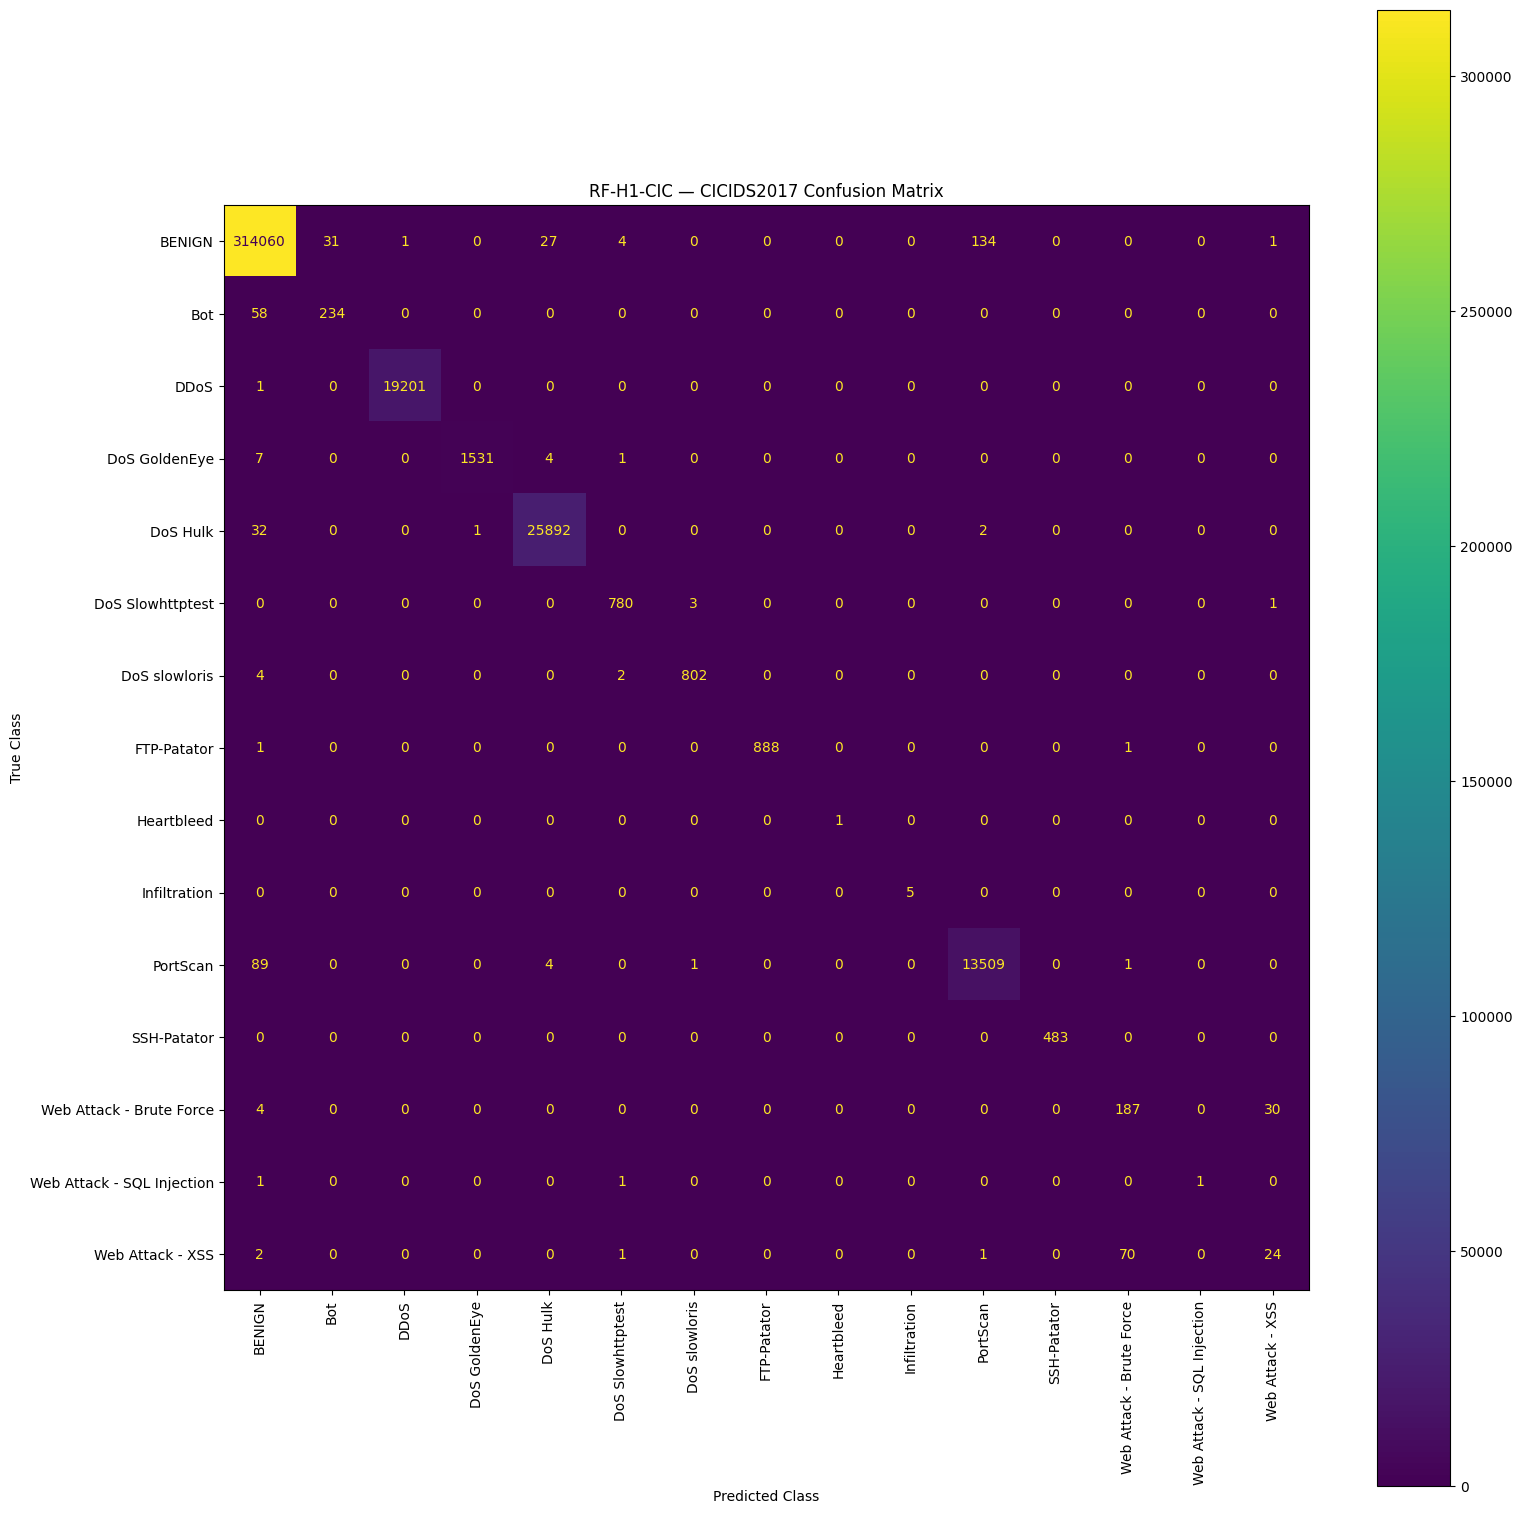


Confusion matrix saved to:
/content/drive/MyDrive/MSc_Project/results/RF_H1_CIC/RF_H1_CIC_confusion_matrix.png

File exists: True


In [ ]:
# Cell 28 — RF-H1-CIC confusion matrix

fig, ax = plt.subplots(
    figsize=(16, 16)
)

ConfusionMatrixDisplay.from_predictions(
    y_true_h1,
    y_pred_h1,
    labels=class_names,
    display_labels=class_names,
    xticks_rotation=90,
    values_format="d",
    ax=ax
)

plt.title(
    "RF-H1-CIC — CICIDS2017 Confusion Matrix"
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "True Class"
)

plt.tight_layout()


# Save confusion matrix
H1_CONFUSION_MATRIX_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H1_CIC_confusion_matrix.png"
)

plt.savefig(
    H1_CONFUSION_MATRIX_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "\nConfusion matrix saved to:"
)

print(
    H1_CONFUSION_MATRIX_PATH
)

print(
    "\nFile exists:",
    os.path.exists(
        H1_CONFUSION_MATRIX_PATH
    )
)

In [ ]:
# Cell 29 — Save RF-H1 final metrics and compare with RF-B baseline

# -------------------------------------------------
# 1. Save final RF-H1-CIC test metrics
# -------------------------------------------------

H1_METRICS_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H1_CIC_metrics.csv"
)

h1_test_metrics_df.to_csv(
    H1_METRICS_PATH,
    index=False
)

print(
    "RF-H1-CIC final metrics saved to:"
)

print(
    H1_METRICS_PATH
)


# -------------------------------------------------
# 2. Load frozen RF-B-CIC baseline metrics
# -------------------------------------------------

BASELINE_METRICS_PATH = os.path.join(
    PROJECT_DIR,
    "results",
    "RF_B_CIC",
    "RF_B_CIC_metrics.csv"
)

if not os.path.exists(BASELINE_METRICS_PATH):
    raise FileNotFoundError(
        f"Baseline metrics not found at: "
        f"{BASELINE_METRICS_PATH}"
    )

baseline_metrics_df = pd.read_csv(
    BASELINE_METRICS_PATH
)

print(
    "\nRF-B-CIC baseline metrics loaded."
)


# -------------------------------------------------
# 3. Add tree count to baseline
# -------------------------------------------------

baseline_metrics_df["Trees"] = 100


# -------------------------------------------------
# 4. Standardise column order
# -------------------------------------------------

comparison_columns = [
    "Model",
    "Trees",
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1",
    "Balanced Accuracy",
    "MCC",
    "Training Time Seconds"
]

baseline_for_comparison = baseline_metrics_df[
    comparison_columns
]

h1_for_comparison = h1_test_metrics_df[
    comparison_columns
]


# -------------------------------------------------
# 5. Create RF-B vs RF-H1 comparison table
# -------------------------------------------------

rf_b_vs_h1 = pd.concat(
    [
        baseline_for_comparison,
        h1_for_comparison
    ],
    ignore_index=True
)

print(
    "\nRF-B-CIC vs RF-H1-CIC Final Test Comparison"
)

display(
    rf_b_vs_h1
)


# -------------------------------------------------
# 6. Save comparison
# -------------------------------------------------

COMPARISON_PATH = os.path.join(
    RESULTS_DIR,
    "RF_B_vs_RF_H1_test_comparison.csv"
)

rf_b_vs_h1.to_csv(
    COMPARISON_PATH,
    index=False
)

print(
    "\nComparison saved to:"
)

print(
    COMPARISON_PATH
)


# -------------------------------------------------
# 7. Final verification
# -------------------------------------------------

print(
    "\nFINAL RF-H1-CIC CHECK"
)

print(
    "H1 metrics exists:",
    os.path.exists(H1_METRICS_PATH)
)

print(
    "H1 classification report exists:",
    os.path.exists(H1_REPORT_PATH)
)

print(
    "H1 confusion matrix exists:",
    os.path.exists(H1_CONFUSION_MATRIX_PATH)
)

print(
    "H1 model exists:",
    os.path.exists(H1_MODEL_SAVE_PATH)
)

print(
    "B vs H1 comparison exists:",
    os.path.exists(COMPARISON_PATH)
)

print(
    "\nRF-H1-CIC experiment is now frozen."
)

RF-H1-CIC final metrics saved to:
/content/drive/MyDrive/MSc_Project/results/RF_H1_CIC/RF_H1_CIC_metrics.csv

RF-B-CIC baseline metrics loaded.

RF-B-CIC vs RF-H1-CIC Final Test Comparison


,Model,Trees,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Training Time Seconds
0,RF-B-CIC,100,0.998606,0.935485,0.879297,0.893851,0.998570,0.879297,0.995364,302.872033
1,RF-H1-CIC,300,0.998622,0.933633,0.879613,0.893381,0.998588,0.879613,0.995417,748.276625



Comparison saved to:
/content/drive/MyDrive/MSc_Project/results/RF_H1_CIC/RF_B_vs_RF_H1_test_comparison.csv

FINAL RF-H1-CIC CHECK
H1 metrics exists: True
H1 classification report exists: True
H1 confusion matrix exists: True
H1 model exists: True
B vs H1 comparison exists: True

RF-H1-CIC experiment is now frozen.
